# Tutorial 2, Problem 3. 

## Hydromethylation of toluene in a PBR

- Description: Program to model the hydrodemethylation of toluene in a PBR with pressure drop and to determine the kinetic parameters from experimental data
- Author: Dr Carlos Avendano
- Last version:  October 2026

In [1]:
# Required Libraries
import numpy as np                     # Library for array manupulations
import matplotlib.pyplot as plt        # Array for plotting
from scipy.integrate import solve_ivp  # ODE solver (Runge-Kutta)
from scipy.optimize import curve_fit     # Curve fitting

## Determination of the kinetic parameters


--- Best-fit parameters ---
k:        144.767308 e-10
K_B:        1.390526
K_T:        1.038411

--- Goodness of fit ---
R2:         0.999951
RMSD:       0.451422

-r_T (exp.)   -r_T (pred.)    |Difference|
   71.000000       71.019701        0.019701
   71.300000       71.019701        0.280299
   41.600000       42.219297        0.619297
   19.700000       19.047036        0.652964
   42.000000       42.219297        0.219297
   17.100000       16.101282        0.998718
   71.800000       71.019701        0.780299
  142.000000      142.039401        0.039401
  284.000000      284.078803        0.078803
   47.000000       47.645736        0.645736
   71.300000       71.019701        0.280299
  117.000000      116.897669        0.102331
  127.000000      127.166168        0.166168
  131.000000      131.001983        0.001983
  133.000000      133.007997        0.007997
   41.800000       42.219297        0.419297


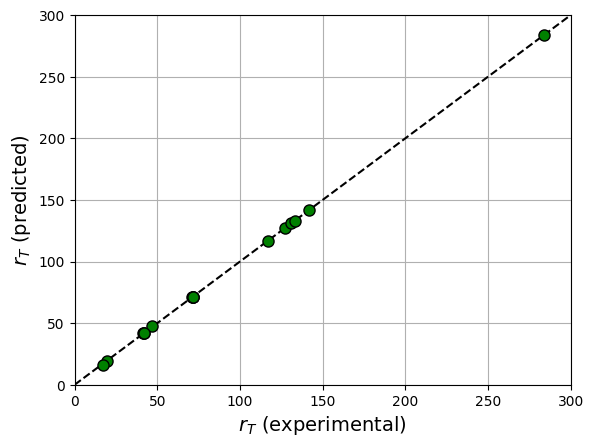

In [2]:
# ---------------------------------------------------------------
# Define the rate equation to be fitted to the experimental data
# ---------------------------------------------------------------
def rate_model(P, k, K_B, K_T):
    """
    Eley-Rideal rate model for the hydrodemethylation of toluene.

    Parameters
    ----------
    P : array
        Partial pressures of the different species.
    k : float
        Reaction rate constant.
    K_B : float
        Adsorption equilibrium constant of benzene.
    K_T : float
        Adsorption equilibrium constant of toluene.

    Returns
    -------
    r_T : array
        Predicted rate of disappearance of toluene.
    """

    # Unpack the partial pressures
    P_T = P[0, :]
    P_H = P[1, :]
    P_M = P[2, :]
    P_B = P[3, :]

    # Calculate the rate of disappearance of toluene
    r_T = k * P_H * P_T / (1.0 + K_B * P_B + K_T * P_T)

    return r_T

# ---------------------------------------------------------------
# Define a function to calculate R^2 and RMSD
# ---------------------------------------------------------------

def metrics(r_exp, r_predicted):
    """
    Calculate the coefficient of determination (R^2) and the
    root-mean-square deviation (RMSD).
    """

    # Average experimental reaction rate
    r_average = np.average(r_exp)

    # Sum of squared residuals
    residuals_sq = np.sum((r_exp - r_predicted)**2)

    # Total sum of squares
    sum_sq = np.sum((r_exp - r_average)**2)

    # Coefficient of determination
    R2 = 1.0 - residuals_sq / sum_sq

    # Root-mean-square deviation
    RMSD = np.sqrt(residuals_sq / r_exp.size)

    return R2, RMSD

# ---------------------------------------------------------------
# Experimental data
# ---------------------------------------------------------------

# Experimental rates of disappearance of toluene.
# The reported values have been multiplied by a factor of 10^10.
r_T = np.array([
    71.0, 71.3, 41.6, 19.7,
    42.0, 17.1, 71.8, 142.0,
    284.0, 47.0, 71.3, 117.0,
    127.0, 131.0, 133.0, 41.8
])


# Experimental partial pressures, atm.
#
# Rows correspond to:
# P_i[0] = P_T
# P_i[1] = P_H2
# P_i[2] = P_M
# P_i[3] = P_B

P_i = np.array([
    [1, 1, 1, 1, 1, 1, 1, 1, 1, 0.5, 1, 5, 10, 15, 20, 1],
    [1, 1, 1, 1, 1, 1, 1, 2, 4, 1,   1, 1,  1,  1,  1, 1],
    [1, 4, 0, 0, 1, 0, 0, 0, 0, 0,   0, 0,  0,  0,  0, 1],
    [0, 0, 1, 4, 1, 5, 0, 0, 0, 0,   0, 0,  0,  0,  0, 1]
])


# ---------------------------------------------------------------
# Fit the kinetic model to the experimental data
# ---------------------------------------------------------------

# Initial guesses for the parameters k, K_B, and K_T
parameters_guess = [0.001, 1.0, 1.0]


# Fit the rate model to the experimental data
popt, pcov = curve_fit(
    rate_model,
    P_i,
    r_T,
    p0=parameters_guess
)

# Extract the optimized kinetic parameters
k_opt = popt[0]
K_B_opt = popt[1]
K_T_opt = popt[2]

# Calculate the reaction rates predicted by the fitted model
r_predicted = rate_model(
    P_i,
    k_opt,
    K_B_opt,
    K_T_opt
)

# Calculate R^2 and RMSD
R2, RMSD = metrics(r_T, r_predicted)

# ---------------------------------------------------------------
# Print the fitted parameters
# ---------------------------------------------------------------
print("\n--- Best-fit parameters ---")

print("k:      {0:12.6f} e-10".format(k_opt))
print("K_B:    {0:12.6f}".format(K_B_opt))
print("K_T:    {0:12.6f}".format(K_T_opt))

print("\n--- Goodness of fit ---")

print("R2:     {0:12.6f}".format(R2))
print("RMSD:   {0:12.6f}".format(RMSD))

# ---------------------------------------------------------------
# Compare experimental and predicted reaction rates
# ---------------------------------------------------------------

print("\n-r_T (exp.)   -r_T (pred.)    |Difference|")

for i in range(r_T.size):

    difference = np.abs(r_T[i] - r_predicted[i])

    print(
        "{0:12.6f} {1:15.6f} {2:15.6f}".format(
            r_T[i],
            r_predicted[i],
            difference
        )
    )


# ---------------------------------------------------------------
# Parity plot
# ---------------------------------------------------------------

# Perfect agreement between experimental and predicted values
plt.plot(
    [0, 300],
    [0, 300],
    color="k",
    linestyle="--",
    label="Perfect agreement"
)

# Experimental versus predicted reaction rates
plt.plot(
    r_T,
    r_predicted,
    marker="o",
    linestyle="None",
    color="k",
    markerfacecolor="g",
    markersize=8,
    label="Eley-Rideal model"
)

plt.xlabel(r'$r_T$ (experimental)',size=14)
plt.ylabel(r'$r_T$ (predicted)',size=14)
plt.xlim([0,300])
plt.ylim([0,300])

plt.grid()

plt.savefig(
    "hydrodemethylation_fitting.pdf",
    bbox_inches="tight"
)

plt.show()

## Define the packed-bed reactor model

Note that the kinetic parameters calculated previously are defined as global variables. They can therefore be accessed directly by the functions and calculations in the remainder of the code.

Important: The experimental reaction rates used in the previous section were multiplied by a factor of $10^{10}$. Therefore, the fitted value of $k$ must first be divided by $10^{10}$ before it is used in the PBR model.

In addition, the units of $k$ must be converted from

\begin{equation*}
    \mathrm{
    \frac{mol}{atm^2
    \,g_{cat}
    \,s}}
\end{equation*}

to

\begin{equation*}
    \mathrm{
    \frac{mol}{atm^2
    \,kg_{cat}
    \,min}}.
\end{equation*}

The required conversion is therefore

\begin{equation*}
k_{
\mathrm{PBR}}
=
\frac{k_{
\mathrm{fit}}}{10^{10}}
\left(
\frac{1000
\ 
\mathrm{g_{cat}}}{1
\ 
\mathrm{kg_{cat}}}
\right)
\left(
\frac{60
\ 
\mathrm{s}}{1
\ 
\mathrm{min}}
\right),
\end{equation*}

or

\begin{equation*}
    \boxed{
    k_{
    \mathrm{PBR}}
    =
    k_{
    \mathrm{fit}}
    \times 6.0
    \times10^{-6}
    }
\end{equation*}

with units of

\begin{equation*}
    \mathrm{
    \frac{mol}{atm^2
    \,kg_{cat}
    \,min}}.
\end{equation*}

In [3]:
def pbr_model(w, z, P0):

    """
    Model of an isothermal packed-bed reactor with pressure drop.

    The reaction is

        T + H2 -> B + M

    State variables
    ---------------
    z[0] = molar flow rate of toluene (T), mol/min
    z[1] = molar flow rate of hydrogen (H2), mol/min
    z[2] = molar flow rate of benzene (B), mol/min
    z[3] = molar flow rate of methane (M), mol/min
    z[4] = molar flow rate of inerts (I), mol/min
    z[5] = dimensionless pressure ratio, p = P/P0

    Parameters
    ----------
    w : float
        Catalyst weight, kg.

    z : array
        Array containing the state variables.

    P0 : float
        Reactor inlet pressure, atm.

    Returns
    -------
    dFT_dW : float
        Change in the molar flow rate of toluene with catalyst weight.

    dFH2_dW : float
        Change in the molar flow rate of hydrogen with catalyst weight.

    dFB_dW : float
        Change in the molar flow rate of benzene with catalyst weight.

    dFM_dW : float
        Change in the molar flow rate of methane with catalyst weight.

    dFI_dW : float
        Change in the molar flow rate of inerts with catalyst weight.

    dp_dW : float
        Change in the dimensionless pressure ratio with catalyst weight.
    """

    # ---------------------------------------------------------------
    # Unpack the state variables
    # ---------------------------------------------------------------

    FT = z[0]
    FH2 = z[1]
    FB = z[2]
    FM = z[3]
    FI = z[4]
    p = z[5]


    # ---------------------------------------------------------------
    # Calculate the total molar flow rate
    # ---------------------------------------------------------------

    F_tot = FT + FH2 + FB + FM + FI


    # ---------------------------------------------------------------
    # Calculate the total pressure
    # ---------------------------------------------------------------

    P = p * P0


    # ---------------------------------------------------------------
    # Calculate the partial pressures
    #
    #     P_i = y_i P = (F_i/F_tot)P
    # ---------------------------------------------------------------

    PT = (FT / F_tot) * P
    PH2 = (FH2 / F_tot) * P
    PB = (FB / F_tot) * P
    PM = (FM / F_tot) * P
    PI = (FI / F_tot) * P


    # ---------------------------------------------------------------
    # Calculate the rate of disappearance of toluene
    # ---------------------------------------------------------------

    # Convert the fitted rate constant from
    # mol/(atm^2 g_cat s) to mol/(atm^2 kg_cat min).
    #
    # The factor of 1e-10 removes the scaling applied to the
    # experimental reaction rates.
    k_pbr = k_opt * 1.0e-10 * 1000.0 * 60.0

    # Eley-Rideal rate model
    rT = (
        -k_pbr * PH2 * PT
        / (1.0 + K_B_opt * PB + K_T_opt * PT)
    )


    # ---------------------------------------------------------------
    # Calculate the rates of formation of all species
    # ---------------------------------------------------------------

    # Stoichiometry:
    #
    #     T + H2 -> B + M

    rH2 = rT
    rB = -rT
    rM = -rT
    rI = 0.0


    # ---------------------------------------------------------------
    # Mole balances
    #
    #     dF_i/dW = r_i'
    # ---------------------------------------------------------------

    dFT_dW = rT
    dFH2_dW = rH2
    dFB_dW = rB
    dFM_dW = rM
    dFI_dW = rI


    # ---------------------------------------------------------------
    # Pressure-drop equation
    #
    #     dp/dW = -alpha/(2p)
    #
    # This simplified expression applies because
    # F_tot/F_tot,0 = 1 for this reaction.
    # ---------------------------------------------------------------

    alpha = 9.8e-5  # kg^(-1)

    dp_dW = -alpha / (2.0 * p)


    # Return the six coupled differential equations
    return [
        dFT_dW,
        dFH2_dW,
        dFB_dW,
        dFM_dW,
        dFI_dW,
        dp_dW
    ]

## Solving the system of differential equations

In [4]:
# ---------------------------------------------------------------
# Define the initial conditions
# ---------------------------------------------------------------

# Reactor inlet pressure, atm
P0 = 40.0


# Initial molar flow rates, mol/min

# Total inlet molar flow rate.
# The feed contains 30% toluene and FT_0 = 50 mol/min.
F_tot_0 = 50.0 / 0.30

# Individual inlet molar flow rates
FT_0 = F_tot_0 * 0.30
FH2_0 = F_tot_0 * 0.45
FB_0 = 0.0
FM_0 = 0.0
FI_0 = F_tot_0 * 0.25


# Initial dimensionless pressure ratio, p = P/P0
p_0 = 1.0


# Initial conditions:
# [FT_0, FH2_0, FB_0, FM_0, FI_0, p_0]
z0 = [FT_0, FH2_0, FB_0, FM_0, FI_0, p_0]


# ---------------------------------------------------------------
# Define the catalyst-weight interval
# ---------------------------------------------------------------


# Maximum catalyst weight, kg
max_w = 10000.0

# Integration interval
w_span = (0.0, max_w)

# Number of points at which the solution will be evaluated
w_steps = 500

# Catalyst-weight array, kg
w_array = np.linspace(0.0, max_w, w_steps)


# ---------------------------------------------------------------
# Solve the system of differential equations
# ---------------------------------------------------------------

solution = solve_ivp(
    pbr_model,
    t_span=w_span,
    y0=z0,
    t_eval=w_array,
    args=(P0,)
)


# ---------------------------------------------------------------
# Extract the results
# ---------------------------------------------------------------

# Catalyst weight, kg
weight = solution.t

# Molar flow rates, mol/min
FT = solution.y[0, :]
FH2 = solution.y[1, :]
FB = solution.y[2, :]
FM = solution.y[3, :]
FI = solution.y[4, :]

# Dimensionless pressure ratio, p = P/P0
pressure_ratio = solution.y[5, :]

# Calculate the total molar flow rate
F_tot = FT + FH2 + FB + FM + FI

# Calculate the mole fractions
yT = FT / F_tot
yH2 = FH2 / F_tot
yB = FB / F_tot
yM = FM / F_tot
yI = FI / F_tot

# Calculate the total pressure
pressure = pressure_ratio * P0

# Calculate the partial pressures
PT =   yT * pressure
PH2 = yH2 * pressure
PB =   yB * pressure
PM =   yM * pressure
PI =   yI * pressure

# Calculate the conversion of toluene
conversion = (FT_0 - FT) / FT_0

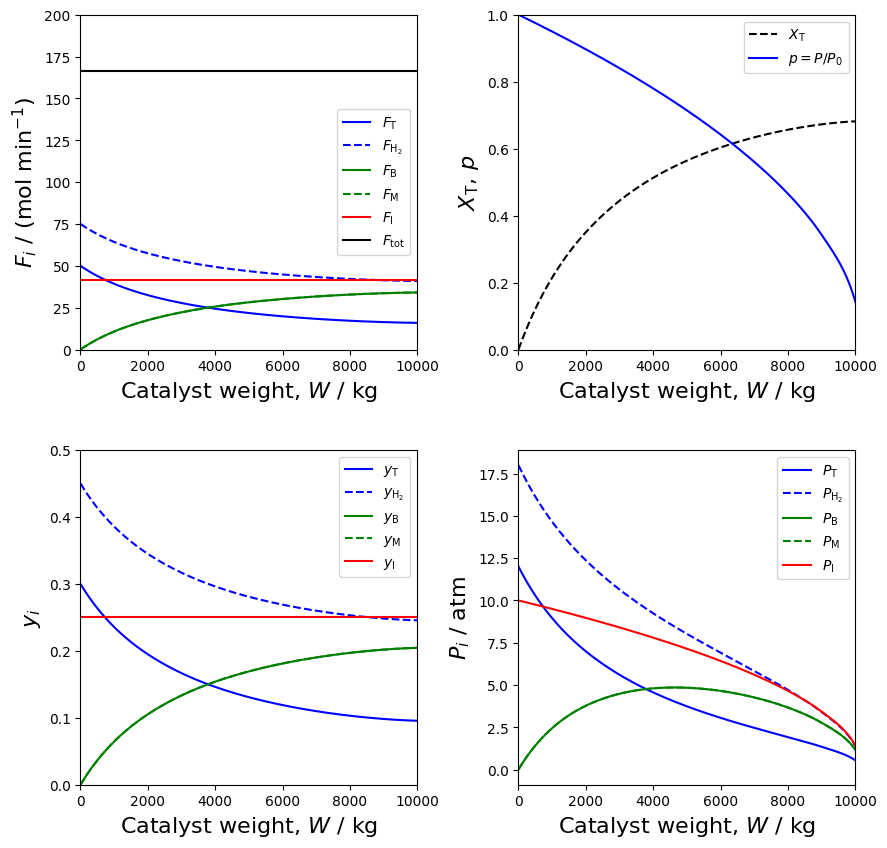

In [5]:
# Plot the reactor profiles

# Create a figure object. The size is given in inches
fig = plt.figure(figsize=(10, 10))

# Create four subplots
ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)

# Adjust the spacing between subplots
plt.subplots_adjust(wspace=0.3, hspace=0.3)


# ---------------------------------------------------------------
# Plot the molar flow rates
# ---------------------------------------------------------------

ax1.plot(weight, FT,    '-b', label=r'$F_\mathrm{T}$')
ax1.plot(weight, FH2,  '--b', label=r'$F_\mathrm{H_2}$')
ax1.plot(weight, FB,    '-g', label=r'$F_\mathrm{B}$')
ax1.plot(weight, FM,   '--g', label=r'$F_\mathrm{M}$')
ax1.plot(weight, FI,    '-r', label=r'$F_\mathrm{I}$')
ax1.plot(weight, F_tot, '-k', label=r'$F_\mathrm{tot}$')

ax1.set_xlabel(r'Catalyst weight, $W$ / kg', size=16)
ax1.set_ylabel(r'$F_i$ / (mol min$^{-1}$)', size=16)

ax1.set_xlim([0, max_w])
ax1.set_ylim([0, 200])

ax1.legend()


# ---------------------------------------------------------------
# Plot the conversion and pressure ratio
# ---------------------------------------------------------------

ax2.plot(
    weight,
    conversion,
    '--k',
    label=r'$X_\mathrm{T}$'
)

ax2.plot(
    weight,
    pressure_ratio,
    '-b',
    label=r'$p=P/P_0$'
)

ax2.set_xlabel(r'Catalyst weight, $W$ / kg', size=16)
ax2.set_ylabel(r'$X_\mathrm{T},\,p$', size=16)

ax2.set_xlim([0, max_w])
ax2.set_ylim([0, 1])

ax2.legend()


# ---------------------------------------------------------------
# Plot the mole fractions
# ---------------------------------------------------------------

ax3.plot(weight, yT,   '-b', label=r'$y_\mathrm{T}$')
ax3.plot(weight, yH2, '--b', label=r'$y_\mathrm{H_2}$')
ax3.plot(weight, yB,   '-g', label=r'$y_\mathrm{B}$')
ax3.plot(weight, yM,  '--g', label=r'$y_\mathrm{M}$')
ax3.plot(weight, yI,   '-r', label=r'$y_\mathrm{I}$')

ax3.set_xlabel(r'Catalyst weight, $W$ / kg', size=16)
ax3.set_ylabel(r'$y_i$', size=16)

ax3.set_xlim([0, max_w])
ax3.set_ylim([0, 0.5])

ax3.legend()


# ---------------------------------------------------------------
# Plot the partial pressures
# ---------------------------------------------------------------

ax4.plot(weight, PT,   '-b', label=r'$P_\mathrm{T}$')
ax4.plot(weight, PH2, '--b', label=r'$P_\mathrm{H_2}$')
ax4.plot(weight, PB,   '-g', label=r'$P_\mathrm{B}$')
ax4.plot(weight, PM,  '--g', label=r'$P_\mathrm{M}$')
ax4.plot(weight, PI,   '-r', label=r'$P_\mathrm{I}$')

ax4.set_xlabel(r'Catalyst weight, $W$ / kg', size=16)
ax4.set_ylabel(r'$P_i$ / atm', size=16)

ax4.set_xlim([0, max_w])

ax4.legend()

# Save figure 
plt.savefig("hydrodemethylation.pdf", bbox_inches='tight')
# Display figure
plt.show()